# Step 2.2: Reliability of GG (OSM / open data) vs GE (ground truth)

This notebook compares, attribute by attribute, the **GG** layer (Grand Genève, mostly OSM) with the **GE** layer (SITG, considered the ground truth) **within the canton of Geneva**. File paths come from `attributs_info_walk_urbain.xlsx` (columns `source_path_GE/GG`, `file_name_GE/GG`), as in `2_1_Filter_features_walk.ipynb`.

**Definitions** (GT = GE, test = GG)

| | meaning |
|---|---|
| TP | object present in both (within the buffer tolerance) |
| FN | GE object **missing** from GG |
| FP | GG object **absent** from GE |
| precision | TP / (TP + FP): how reliable GG is |
| recall | TP / (TP + FN): how complete GG is |
| F1 | 2·P·R / (P + R) |

**Comparison method by geometry type** (chosen automatically)

* **point**: one-to-one matching with the nearest neighbour within `buffer` m (each object can only be matched once). Metrics are **counts**.
* **line**: length-based. Recall = share of GE length lying within `buffer` m of GG (*completeness*), precision = share of GG length within `buffer` m of GE (*correctness*). A feature is FN/FP if less than `LINE_MIN_SHARE` of its length is covered.
* **polygon**: the same idea, using **area**. Recall = share of GE area covered by GG buffered by `buffer` m, precision = share of GG area covered by GE buffered by `buffer` m. A polygon is FN/FP if less than `POLY_MIN_SHARE` of its area is covered. The buffer absorbs digitisation offsets at the edges. Counting polygons does not work because OSM and SITG split or merge objects differently (one lake = 1 or 12 polygons).
* **vitesse**: specific function `vitesse_metrics` (OTC zones vs OSM `speed_kph`), see the dedicated section.
* **polygon_line** (one layer polygons, the other lines, e.g. `chemin`): the **polygon** side is measured by the share of its **area** covered by the lines buffered by `buffer` m (flat caps, buffer around the lines only); the **line** side by the share of its **length** inside the polygons buffered by `buffer` m. With GE polygons / GG lines: recall = area share, precision = length share. A polygon is FN if < `POLY_MIN_SHARE` of its area is covered, a line is FP if < `LINE_MIN_SHARE` of its length is inside.
* **mixed** (other geometry mismatches, e.g. points vs lines): placeholder function `mixed_metrics`, still to be specified.

In [13]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import pyogrio
import matplotlib.pyplot as plt
from shapely.geometry.base import BaseGeometry
pd.set_option('display.max_columns', None)

## Parameters

In [14]:
operation_crs = "EPSG:2056"   # metric CRS: every buffer is in metres
network = "walk"

input_file_path = '../../Data/input'
attributs_info_path = f"{input_file_path}/attributs/attributs_info_{network}_urbain.xlsx"

###----change here-----
# Border of the canton (lines or polygons: lines are polygonised automatically)
domain_path = f"{input_file_path}/network_agreg/CAD_LIMITE_CANTON-SHP/CAD_LIMITE_CANTON.shp"

# Output directory: one sub-folder per attribute is created inside
output_comparison_path = f"../../Data/output/{network}/comparison_GG_vs_GE"

attribute = 'chemin'                 # attribute to compare (column 'attribute' of the Excel)

# "excel": raw files from the Excel paths (+ RAW_FILTERS below)
# "step2": filtered outputs of 2_1 (Data/output/{network}/{GE|GG}/step-2/gpkg_attributs/{attribute}.gpkg, filtered == 1)
DATA_SOURCE = "step2"

BUFFER_EXPORT = 10                     # [m] buffer used to export FN / FP
BUFFER_RANGE = np.arange(1, 51, 10)     # [m] buffers for the precision / recall / F1 curve

LINE_MIN_SHARE = 0.5   # a line is matched if >= 50 % of its length is covered
POLY_MIN_SHARE = 0.5   # a polygon is matched if >= 50 % of its area is covered

# Attributes always sent to the generic mixed comparison (placeholder)
MIXED_ATTRIBUTES = set()

# --- vitesse only (attribute-specific comparison) ---
SPEED_TOL_EXPORT = 10                    # [km/h] tolerance used to export FN / FP
SPEED_TOL_RANGE = np.arange(0, 31, 5)    # [km/h] tolerances for the precision / recall / F1 curve
SPEED_MIN_SHARE = 0.5                    # a GG line is matched to an OTC zone if > 50 % of it lies in it
SPEED_ZONE_BUFFER = 50                    # [m] buffer around OTC zones: lines not matched to a real zone get a 2nd chance
                                         #     against the buffered zones (OSM offset, lines just outside a zone)
SPEED_LINE_BUFFER = 0                    # [m] buffer around GG segments for the spatial match (0 = plain lines, share by length;
                                         #     > 0 = flat-ended buffer, share by area of the buffered segment)
GG_SPEED_COL = "speed_kph"               # speed column of the GG lines
GE_SPEED_LABEL_COL = "TYPE_LIMIT"        # label column of the OTC zones
###--------------------

# Force a layer in a multi-layer GeoPackage: {(territory, attribute): layer_name}
# By default: the only layer, otherwise 'meta_attribute', otherwise 'attribute' (as in 2_1)
LAYER_OVERRIDE = {
    # ("GG", "zone_pietonne"): "zone_pietonne_area",
}

# Filters applied in "excel" mode (copy of the simple filters of 2_1).
# Complex filters (rez_actif, amenite, chemin GG, zone_pietonne GG...) -> use DATA_SOURCE = "step2"
RAW_FILTERS = {
    ("GE", "lac_cours_deau"):  lambda g: g[g.GENRE.isin(["eau stagnante", "cours d'eau"])],
    ("GE", "zone_pietonne"):   lambda g: g[g.TYPE_ZONE.isin(['Zone piétonne', 'Zone de rencontre (20)'])],
    # ("GE", "vitesse"): lambda g: g[g.TYPE_ZONE == 0],   # disabled: vitesse needs every OTC zone (see OTC_SPEED_MAP)
    ("GE", "zone_apaisee"):    lambda g: g[g.TYPE_LIMIT.isin(['Zone 30 km/h', 'Prescription 30 km/h', 'Prescription 20 km/h'])],
    ("GG", "zone_apaisee"):    lambda g: g[(g.speed_kph > 5) & (g.speed_kph < 30)],
    ("GE", "espaces_ouverts"): lambda g: g[g.TYPE == 'ESPACE PUBLIC'],
    ("GE", "chemin"):          lambda g: g[g.OBJET == "Chemin"],
}

## Helper functions (loading, domain, geometry)

In [15]:
UNAVAILABLE = {"nan", "none", "", "unavailable", "n/a"}
RASTER_EXT = {".tif", ".tiff", ".vrt", ".asc"}


def clean_any_geom(geom):
    """Same logic as 2_1: repair invalid geometries, drop non-geometries."""
    if geom is None or not isinstance(geom, BaseGeometry):
        return None
    if geom.is_valid:
        return geom
    try:
        fixed = shapely.make_valid(geom)
        return geom if fixed is None or fixed.is_empty else fixed
    except Exception:
        return geom


def read_vector(path, layer=None):
    ext = os.path.splitext(path)[1].lower()
    if ext == ".parquet":
        return gpd.read_parquet(path)
    try:
        return gpd.read_file(path, layer=layer)
    except UnicodeDecodeError:
        return gpd.read_file(path, layer=layer, encoding="latin1")


def resolve_layer(path, row, territory):
    key = (territory, row["attribute"])
    if key in LAYER_OVERRIDE:
        return LAYER_OVERRIDE[key]
    if not path.lower().endswith(".gpkg"):
        return None
    layers = list(pyogrio.list_layers(path)[:, 0])
    if len(layers) == 1:
        return layers[0]
    for cand in (row["meta_attribute"], row["attribute"]):
        if cand in layers:
            return cand
    raise ValueError(f"{path}: cannot choose a layer for '{row['attribute']}'. "
                     f"Available layers: {layers}. Fill LAYER_OVERRIDE.")


def load_attribute_layer(row, territory):
    """Load the GE or GG layer of an attribute (raw Excel path or step-2 output)."""
    attr = row["attribute"]
    if DATA_SOURCE == "step2":
        base = f"../../Data/output/{network}/{territory}/step-2"
        candidates = [f"{base}/gpkg_attributs/{attr}.gpkg", f"{base}/parquet_attributs/{attr}.parquet"]
        path = next((p for p in candidates if os.path.exists(p)), None)
        if path is None:
            raise FileNotFoundError(f"No step-2 output for {attr} ({territory}): run 2_1 first. Tried {candidates}")
        gdf = read_vector(path)
        if "filtered" in gdf.columns:
            gdf = gdf[gdf["filtered"] == 1]
        print(f"[{territory}] {path}  ->  {len(gdf):,} features (filtered == 1)")
    else:
        src, fname = row[f"source_path_{territory}"], row[f"file_name_{territory}"]
        if str(src).strip().lower() in UNAVAILABLE or str(fname).strip().lower() in UNAVAILABLE:
            raise ValueError(f"'{attr}' is not available for {territory} in the Excel.")
        path = f"{input_file_path}/{src}/{fname}"
        if os.path.splitext(path)[1].lower() in RASTER_EXT:
            raise ValueError(f"'{attr}' ({territory}) is a raster ({path}): vector comparison not applicable.")
        layer = resolve_layer(path, row, territory)
        gdf = read_vector(path, layer=layer)
        n_raw = len(gdf)
        filt = RAW_FILTERS.get((territory, attr))
        if filt is not None:
            gdf = filt(gdf)
        print(f"[{territory}] {path}" + (f" (layer={layer})" if layer else "")
              + f"  ->  {n_raw:,} features, {len(gdf):,} after filter" + (" (RAW_FILTERS)" if filt else " (no filter)"))

    if gdf.crs is None:
        print(f"  Warning: no CRS, assuming EPSG:{int(row['crs'])}")
        gdf = gdf.set_crs(epsg=int(row["crs"]))
    gdf = gdf.to_crs(operation_crs)
    gdf["geometry"] = gdf["geometry"].apply(clean_any_geom)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
    return gdf.reset_index(drop=True)


def load_domain(path):
    """Canton polygon. If the file contains border lines, they are polygonised."""
    d = read_vector(path).to_crs(operation_crs)
    polys = d[d.geom_type.isin(["Polygon", "MultiPolygon"])]
    if len(polys):
        geom = shapely.union_all(polys.geometry.values)
    else:
        merged = shapely.union_all(d.geometry.values)          # node the lines
        faces = shapely.get_parts(shapely.polygonize(shapely.get_parts(merged)))
        if len(faces) == 0:
            raise ValueError("Border lines do not form a closed ring: cannot polygonise.")
        geom = shapely.union_all(faces)
    return shapely.make_valid(geom)


def geom_family(gdf):
    """Dominant geometry family: 'point', 'line' or 'polygon'."""
    fam = gdf.geom_type.map({"Point": "point", "MultiPoint": "point",
                             "LineString": "line", "MultiLineString": "line", "LinearRing": "line",
                             "Polygon": "polygon", "MultiPolygon": "polygon"})
    counts = fam.value_counts()
    if counts.empty:
        return None, counts
    return counts.index[0], counts


def harmonize(gdf, family):
    """Keep only the target family. For points, OSM polygons (POIs mapped as areas) become representative points."""
    gdf = gdf.explode(index_parts=False, ignore_index=True)
    if family == "point":
        poly = gdf.geom_type == "Polygon"
        if poly.any():
            print(f"  {poly.sum():,} polygon(s) converted to points (representative_point)")
            gdf.loc[poly, "geometry"] = gdf.loc[poly].geometry.representative_point()
    keep = {"point": ["Point"], "line": ["LineString", "LinearRing"], "polygon": ["Polygon"]}[family]
    dropped = (~gdf.geom_type.isin(keep)).sum()
    if dropped:
        print(f"  {dropped:,} feature(s) of another geometry type dropped")
    return gdf[gdf.geom_type.isin(keep)].reset_index(drop=True)

## Comparison functions

All functions share the same signature `f(gt, test, buffer) -> (metrics: dict, fn: GeoDataFrame, fp: GeoDataFrame)` so the sweep and the export work identically whatever the geometry type.

In [16]:
def _prf(precision, recall):
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"precision": precision, "recall": recall, "F1": f1}


def point_metrics(gt, test, buffer):
    """One-to-one matching: each GT point is paired with the nearest test point within `buffer` m.
    Duplicates are removed by increasing distance (greedy matching)."""
    if len(gt) == 0 or len(test) == 0:
        return {"TP": 0, "FN": len(gt), "FP": len(test), **_prf(0.0, 0.0)}, gt, test
    pairs = gpd.sjoin_nearest(gt[["geometry"]], test[["geometry"]], how="inner",
                              max_distance=max(buffer, 1e-9), distance_col="dist")
    pairs = (pairs.reset_index(names="i_gt").sort_values("dist", kind="stable")
                  .drop_duplicates("i_gt").drop_duplicates("index_right"))
    tp = len(pairs)
    fn = gt.drop(index=pairs["i_gt"])
    fp = test.drop(index=pairs["index_right"])
    m = {"TP": tp, "FN": len(fn), "FP": len(fp), **_prf(tp / len(test), tp / len(gt))}
    return m, fn, fp


def _covered_measure(target, reference, buffer, measure, cap_style="round"):
    """For each target geometry: length/area (via `measure`) lying within `buffer` m of the reference layer.
    Uses an STRtree, so only nearby reference geometries are merged.
    cap_style="flat": the reference is buffered around lines only, not beyond their end points."""
    out = np.zeros(len(target))
    if len(target) == 0 or len(reference) == 0:
        return out
    ref = shapely.buffer(reference, buffer, cap_style=cap_style) if buffer > 0 else reference
    tree = shapely.STRtree(ref)
    it, ir = tree.query(target, predicate="intersects")
    if len(it) == 0:
        return out
    order = np.argsort(it, kind="stable")
    it, ir = it[order], ir[order]
    splits = np.flatnonzero(np.diff(it)) + 1
    for t_idx, r_idx in zip(np.split(it, splits), np.split(ir, splits)):
        local = ref[r_idx[0]] if len(r_idx) == 1 else shapely.union_all(ref[r_idx])
        out[t_idx[0]] = measure(shapely.intersection(target[t_idx[0]], local))
    return out


def _extent_metrics(gt, test, buffer, measure, min_share, unit):
    """Shared logic for lines (length) and polygons (area)."""
    g, t = gt.geometry.values, test.geometry.values
    gt_tot, test_tot = measure(g), measure(t)
    gt_cov = _covered_measure(g, t, buffer, measure)    # GT covered by test -> recall
    test_cov = _covered_measure(t, g, buffer, measure)  # test covered by GT -> precision
    recall = gt_cov.sum() / gt_tot.sum() if gt_tot.sum() > 0 else 0.0
    precision = test_cov.sum() / test_tot.sum() if test_tot.sum() > 0 else 0.0
    gt_share = np.divide(gt_cov, gt_tot, out=np.zeros_like(gt_cov), where=gt_tot > 0)
    test_share = np.divide(test_cov, test_tot, out=np.zeros_like(test_cov), where=test_tot > 0)
    fn = gt[gt_share < min_share].assign(covered_share=gt_share[gt_share < min_share])
    fp = test[test_share < min_share].assign(covered_share=test_share[test_share < min_share])
    m = {"TP": int((gt_share >= min_share).sum()), "FN": len(fn), "FP": len(fp),
         f"GT_total_{unit}": gt_tot.sum(), f"test_total_{unit}": test_tot.sum(),
         f"GT_covered_{unit}": gt_cov.sum(), f"test_covered_{unit}": test_cov.sum(),
         **_prf(precision, recall)}
    return m, fn, fp


def line_metrics(gt, test, buffer):
    """Length-based completeness (recall) / correctness (precision)."""
    return _extent_metrics(gt, test, buffer, shapely.length, LINE_MIN_SHARE, "m")


def polygon_metrics(gt, test, buffer):
    """Area-based: share of GT area covered by buffered test, and conversely."""
    return _extent_metrics(gt, test, buffer, shapely.area, POLY_MIN_SHARE, "m2")


def poly_line_metrics(gt, test, buffer):
    """Polygons vs lines (e.g. chemin: GE polygons, GG lines). Works in both orientations.
    - Polygon side: share of its AREA covered by the lines buffered by `buffer` m
      (flat caps: the buffer goes around the lines, not beyond their ends).
    - Line side: share of its LENGTH lying inside the polygons buffered by `buffer` m.
    The polygon side is not compared area-to-area with the buffered lines: the buffered strip is 2*buffer wide
    whatever the real width of the polygon, so an area-based precision would drop when the buffer grows."""
    gt_is_poly = geom_family(gt)[0] == "polygon"
    polys, lines = (gt, test) if gt_is_poly else (test, gt)
    P, L = polys.geometry.values, lines.geometry.values
    p_tot, l_tot = shapely.area(P), shapely.length(L)
    p_cov = _covered_measure(P, L, buffer, shapely.area, cap_style="flat")   # polygon area under buffered lines
    l_cov = _covered_measure(L, P, buffer, shapely.length)                   # line length inside buffered polygons
    p_share = np.divide(p_cov, p_tot, out=np.zeros_like(p_cov), where=p_tot > 0)
    l_share = np.divide(l_cov, l_tot, out=np.zeros_like(l_cov), where=l_tot > 0)
    p_bad, l_bad = p_share < POLY_MIN_SHARE, l_share < LINE_MIN_SHARE
    p_out = polys[p_bad].assign(covered_share=p_share[p_bad])
    l_out = lines[l_bad].assign(covered_share=l_share[l_bad])
    p_score = p_cov.sum() / p_tot.sum() if p_tot.sum() > 0 else 0.0
    l_score = l_cov.sum() / l_tot.sum() if l_tot.sum() > 0 else 0.0
    if gt_is_poly:
        recall, precision, fn, fp, tp = p_score, l_score, p_out, l_out, int((~p_bad).sum())
    else:
        recall, precision, fn, fp, tp = l_score, p_score, l_out, p_out, int((~l_bad).sum())
    m = {"TP": tp, "FN": len(fn), "FP": len(fp),
         "poly_total_m2": p_tot.sum(), "poly_covered_m2": p_cov.sum(),
         "line_total_m": l_tot.sum(), "line_inside_m": l_cov.sum(),
         **_prf(precision, recall)}
    return m, fn, fp


def mixed_metrics(gt, test, buffer):
    """DUMMY - comparison across geometry types (e.g. vitesse: GE polygons vs GG lines).
    To be specified later (e.g. share of GG line length inside GE zones + speed value agreement).
    Returns NaN metrics and empty FN/FP so the rest of the notebook keeps running."""
    nan = float("nan")
    return ({"TP": nan, "FN": nan, "FP": nan, "precision": nan, "recall": nan, "F1": nan},
            gt.iloc[0:0], test.iloc[0:0])


COMPARATORS = {"point": point_metrics, "line": line_metrics, "polygon": polygon_metrics}

### Attribute-specific comparison: `vitesse`

GE = OTC speed zones (polygons, label `TYPE_LIMIT`), GG = OSM edges (lines, `speed_kph`).

1. Each `TYPE_LIMIT` is translated into a speed with `OTC_SPEED_MAP`.
2. **Spatial match**: a GG line is matched to the OTC zone containing the largest part of it, if that part is **> `SPEED_MIN_SHARE`** (50 %) of it. Otherwise the line is *outside zones* and not evaluated. With `SPEED_LINE_BUFFER = 0` the share is computed on length; with `SPEED_LINE_BUFFER > 0` each segment is buffered (flat ends) and the share is computed on the **area** of the buffered segment. The exported FN/FP keep the original line geometry.
   With `SPEED_ZONE_BUFFER > 0`, lines not matched to a real zone get a second chance against the zones buffered by that distance (useful when OSM lines lie a few metres outside a zone). Real zones always have priority, so a line inside zone A is never reassigned to the buffer of a neighbouring zone B. Column `match_type` = `inside_zone` / `buffered_zone`.
3. **Speed match**: a matched line is correct if `|speed_kph - speed_OTC| <= tol` (e.g. 30 vs 40 is correct for tol = 10).

Metrics (length-weighted, over spatially matched lines):

| | definition |
|---|---|
| TP | matched line, speed within tolerance |
| FP | matched line, speed **outside** tolerance (wrong speed in GG) → exported as FP |
| FN | matched line **without** speed in GG → exported as FN |
| precision | length TP / length of matched lines with a speed: *when GG gives a speed, is it right?* |
| recall | length TP / length of all matched lines: *how much of the OTC-covered network gets the right speed?* |

The sweep varies the **speed tolerance** (km/h), not a buffer: the spatial matching is computed once.

In [17]:
OTC_SPEED_MAP = {
    "Limite générale 50 km/h": 50,
    "Autoroute - 80 km/h": 80,
    "Autoroute - 100 km/h": 100,
    "Autoroute - 120 km/h": 120,
    "Prescription 20 km/h": 20,
    "Prescription 30 km/h": 30,
    "Prescription 40 km/h": 40,
    "Prescription 50 km/h": 50,
    "Prescription 60 km/h": 60,
    "Prescription 70 km/h": 70,
    "Prescription 80 km/h": 80,   # your list said 30: assumed to be a typo, check
    "Zone 30 km/h": 30,
    "Zone de rencontre": 20,
    "Zone de rencontre (20)": 20, # spelling used in the zone_pietonne filter of 2_1
    "Zone piétonne": 5,
}

_vitesse_cache = {}


def _vitesse_match(gt, test):
    """Spatial matching GG lines -> OTC zones (independent of the speed tolerance, computed once)."""
    key = (id(gt), id(test), len(gt), len(test), SPEED_LINE_BUFFER, SPEED_ZONE_BUFFER, SPEED_MIN_SHARE)
    if key in _vitesse_cache:
        return _vitesse_cache[key]

    zones = gt.explode(index_parts=False, ignore_index=True)
    zones = zones[zones.geom_type == "Polygon"].copy()
    zones["speed_otc"] = zones[GE_SPEED_LABEL_COL].map(OTC_SPEED_MAP)
    unknown = zones.loc[zones["speed_otc"].isna(), GE_SPEED_LABEL_COL].value_counts(dropna=False)
    if len(unknown):
        print(f"Warning: {unknown.sum():,} OTC zone(s) with a {GE_SPEED_LABEL_COL} missing from OTC_SPEED_MAP (ignored):")
        print(unknown.to_string())
    zones = zones[zones["speed_otc"].notna()].reset_index(drop=True)

    lines = test.explode(index_parts=False, ignore_index=True)
    lines = lines[lines.geom_type == "LineString"].copy()
    lines["length_m"] = lines.length
    lines = lines[lines["length_m"] > 0].reset_index(drop=True)
    lines["speed_gg"] = pd.to_numeric(lines[GG_SPEED_COL], errors="coerce")

    lg, zg = lines.geometry.values, zones.geometry.values
    if SPEED_LINE_BUFFER > 0:
        # flat caps: the buffer does not extend beyond the segment ends
        mg, measure = shapely.buffer(lg, SPEED_LINE_BUFFER, cap_style="flat"), shapely.area
    else:
        mg, measure = lg, shapely.length
    total = measure(mg)
    zgb = shapely.buffer(zg, SPEED_ZONE_BUFFER) if SPEED_ZONE_BUFFER > 0 else zg
    il, iz = shapely.STRtree(zgb).query(mg, predicate="intersects")
    cand = pd.DataFrame({"il": il, "iz": iz})
    cand["share_in"] = measure(shapely.intersection(mg[il], zg[iz])) / total[il]
    cand["share_buf"] = (measure(shapely.intersection(mg[il], zgb[iz])) / total[il]
                         if SPEED_ZONE_BUFFER > 0 else cand["share_in"])

    # Pass 1: real OTC zones have priority (a line inside zone A stays in A,
    # even if it is also inside the buffer of the neighbouring zone B)
    p1 = cand.sort_values("share_in", ascending=False).drop_duplicates("il")
    p1 = p1[p1["share_in"] > SPEED_MIN_SHARE].assign(share=lambda d: d["share_in"], match_type="inside_zone")
    best = p1
    # Pass 2: remaining lines are matched against the buffered zones
    if SPEED_ZONE_BUFFER > 0:
        rest = cand[~cand["il"].isin(p1["il"])]
        p2 = rest.sort_values(["share_buf", "share_in"], ascending=False).drop_duplicates("il")
        p2 = p2[p2["share_buf"] > SPEED_MIN_SHARE].assign(share=lambda d: d["share_buf"], match_type="buffered_zone")
        best = pd.concat([p1, p2], ignore_index=True)

    lines["share_in_zone"] = 0.0
    lines["match_type"] = "outside_zones"
    lines["TYPE_LIMIT_otc"] = None
    lines["speed_otc"] = np.nan
    lines.loc[best["il"], "share_in_zone"] = best["share"].values
    lines.loc[best["il"], "match_type"] = best["match_type"].values
    lines.loc[best["il"], "TYPE_LIMIT_otc"] = zones[GE_SPEED_LABEL_COL].values[best["iz"]]
    lines.loc[best["il"], "speed_otc"] = zones["speed_otc"].values[best["iz"]]

    _vitesse_cache[key] = lines
    return lines


def vitesse_metrics(gt, test, tol):
    """vitesse: OTC zones (GE) vs OSM speed_kph (GG), tolerance `tol` in km/h. Length-weighted."""
    lines = _vitesse_match(gt, test)
    m = lines[lines["speed_otc"].notna()]
    has = m["speed_gg"].notna()
    diff = m["speed_gg"] - m["speed_otc"]
    agree = has & (diff.abs() <= tol + 1e-9)
    L = m["length_m"]
    L_matched, L_with_speed, L_agree = L.sum(), L[has].sum(), L[agree].sum()
    precision = L_agree / L_with_speed if L_with_speed > 0 else 0.0
    recall = L_agree / L_matched if L_matched > 0 else 0.0
    fp = m[has & ~agree].assign(diff_kph=diff[has & ~agree])   # wrong speed in GG
    fn = m[~has]                                              # no speed in GG
    metrics = {"TP": int(agree.sum()), "FN": len(fn), "FP": len(fp), "zone_buffer_m": SPEED_ZONE_BUFFER, "line_buffer_m": SPEED_LINE_BUFFER,
               "n_lines_matched": len(m), "n_matched_via_zone_buffer": int((m["match_type"] == "buffered_zone").sum()),
               "n_lines_outside_zones": len(lines) - len(m),
               "km_matched": L_matched / 1e3, "km_outside_zones": (lines["length_m"].sum() - L_matched) / 1e3,
               "km_correct_speed": L_agree / 1e3,
               **_prf(precision, recall)}
    return metrics, fn, fp


SPECIFIC_COMPARATORS = {"vitesse": vitesse_metrics}   # attribute-specific functions take priority


def select_comparison(attr, fam_gt, fam_test):
    if attr in SPECIFIC_COMPARATORS:
        return SPECIFIC_COMPARATORS[attr], attr
    if attr in MIXED_ATTRIBUTES:
        return mixed_metrics, "mixed"
    if {fam_gt, fam_test} == {"polygon", "line"}:
        return poly_line_metrics, "polygon_line"
    if fam_gt != fam_test:
        return mixed_metrics, "mixed"
    return COMPARATORS[fam_gt], fam_gt

## Load the Excel, the domain and both layers

In [18]:
attributs_info = pd.read_excel(attributs_info_path, sheet_name="attributs_info")
if attribute not in set(attributs_info["attribute"]):
    raise ValueError(f"'{attribute}' not in the Excel. Available: {sorted(attributs_info['attribute'])}")
row = attributs_info[attributs_info["attribute"] == attribute].iloc[0]
print(f"Attribute: {attribute} | Excel geometry GE={row['geometry_type_GE']} GG={row['geometry_type_GG']}")

same_src = (str(row["source_path_GE"]) == str(row["source_path_GG"])
            and str(row["file_name_GE"]) == str(row["file_name_GG"]))
if str(row["source_type_GE"]).lower() == "osm" or same_src:
    print("Warning: the GE source is OSM (or the same file as GG): this is not a comparison with an independent ground truth.")

domain = load_domain(domain_path)
print(f"Domain (canton GE): {domain.area / 1e6:,.1f} km2")

Attribute: chemin | Excel geometry GE=polygon GG=line
Domain (canton GE): 282.5 km2


In [19]:
gt = load_attribute_layer(row, "GE")    # ground truth
test = load_attribute_layer(row, "GG")  # data to evaluate

# Restrict both layers to the canton (clip cuts lines/polygons at the border)
gt = gpd.clip(gt, domain).reset_index(drop=True)
test = gpd.clip(test, domain).reset_index(drop=True)

fam_gt, counts_gt = geom_family(gt)
fam_test, counts_test = geom_family(test)
print(f"GE in canton: {len(gt):,} features | {counts_gt.to_dict()}")
print(f"GG in canton: {len(test):,} features | {counts_test.to_dict()}")

compare, method = select_comparison(attribute, fam_gt, fam_test)
print(f"-> comparison method: {method} ({compare.__name__})")
if method in COMPARATORS or method == "polygon_line":
    gt, test = harmonize(gt, fam_gt), harmonize(test, fam_test)

# Sweep parameter: buffer in m (generic) or speed tolerance in km/h (vitesse)
if method == "vitesse":
    PARAM_EXPORT, PARAM_RANGE, PARAM_NAME, PARAM_UNIT = SPEED_TOL_EXPORT, SPEED_TOL_RANGE, "speed tolerance", "kmh"
else:
    PARAM_EXPORT, PARAM_RANGE, PARAM_NAME, PARAM_UNIT = BUFFER_EXPORT, BUFFER_RANGE, "buffer", "m"

[GE] ../../Data/output/walk/GE/step-2/gpkg_attributs/chemin.gpkg  ->  3,797 features (filtered == 1)
[GG] ../../Data/output/walk/GG/step-2/gpkg_attributs/chemin.gpkg  ->  26,407 features (filtered == 1)
GE in canton: 3,797 features | {'polygon': 3797}
GG in canton: 6,946 features | {'line': 6946}
-> comparison method: polygon_line (poly_line_metrics)


/var/folders/rf/gj35881j7ydf0dq8kldyt7nw0000gn/T/ipykernel_1967/2176419421.py:6: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(); ax.set_title(f"{attribute}: GE (blue) vs GG (orange)"); ax.set_axis_off()


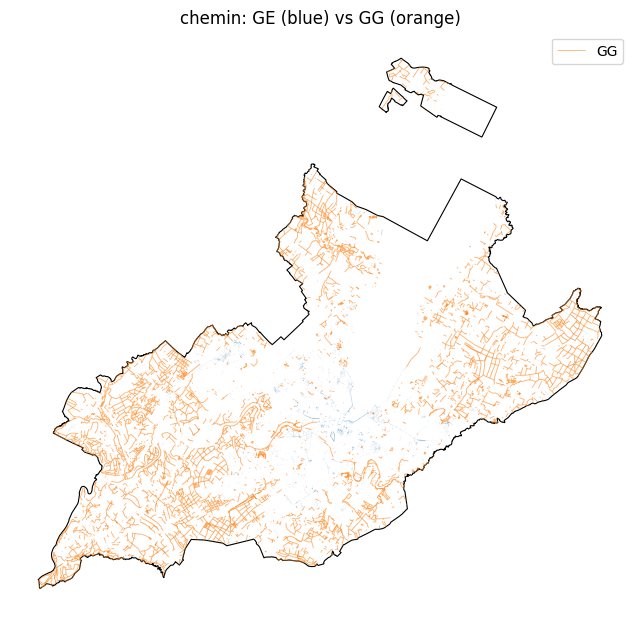

In [20]:
# Quick visual check
fig, ax = plt.subplots(figsize=(8, 8))
gpd.GeoSeries([domain], crs=operation_crs).boundary.plot(ax=ax, color="black", linewidth=0.8)
test.plot(ax=ax, color="tab:orange", markersize=3, linewidth=0.6, alpha=0.6, label="GG")
gt.plot(ax=ax, color="tab:blue", markersize=3, linewidth=0.6, alpha=0.6, label="GE (GT)")
ax.legend(); ax.set_title(f"{attribute}: GE (blue) vs GG (orange)"); ax.set_axis_off()
plt.show()

## Comparison at `BUFFER_EXPORT` (`SPEED_TOL_EXPORT` for vitesse) and export of FN / FP

In [21]:
out_dir = os.path.join(output_comparison_path, attribute)
os.makedirs(out_dir, exist_ok=True)
ptag = "tol" if method == "vitesse" else "buffer"
btag = f"{PARAM_EXPORT:g}{PARAM_UNIT}"


def save_gpkg(gdf, path, layer):
    if gdf is None or len(gdf) == 0:
        print(f"  {layer}: empty, nothing written")
        return
    gdf.to_file(path, layer=layer, driver="GPKG")
    print(f"  {layer}: {len(gdf):,} features -> {path}")


metrics, fn, fp = compare(gt, test, PARAM_EXPORT)
print(f"[{attribute} | {method} | {PARAM_NAME} = {btag}]")
for k, v in metrics.items():
    print(f"  {k:>18}: {v:,.3f}" if isinstance(v, float) else f"  {k:>18}: {v:,}")

save_gpkg(fn, os.path.join(out_dir, f"{attribute}_FN_missing_in_GG_{ptag}{btag}.gpkg"), f"FN_{attribute}")
if method == "vitesse":
    # Length (km) by OTC speed (rows) and GG speed (columns), spatially matched lines only
    _m = _vitesse_match(gt, test).query("speed_otc == speed_otc")
    print("\nLength [km] by OTC speed (rows) x GG speed_kph (columns):")
    display(pd.crosstab(_m["speed_otc"], _m["speed_gg"].fillna(-1).rename("speed_gg (-1 = missing)"),
                        values=_m["length_m"] / 1e3, aggfunc="sum").round(1).fillna(0))

save_gpkg(fp, os.path.join(out_dir, f"{attribute}_FP_{'wrong_speed_in_GG' if method == 'vitesse' else 'absent_from_GE'}_{ptag}{btag}.gpkg"), f"FP_{attribute}")

[chemin | polygon_line | buffer = 10m]
                  TP: 1,310
                  FN: 2,487
                  FP: 4,982
       poly_total_m2: 2,018,716.181
     poly_covered_m2: 885,834.928
        line_total_m: 951,292.238
       line_inside_m: 321,439.962
           precision: 0.338
              recall: 0.439
                  F1: 0.382
  FN_chemin: 2,487 features -> ../../Data/output/walk/comparison_GG_vs_GE/chemin/chemin_FN_missing_in_GG_buffer10m.gpkg
  FP_chemin: 4,982 features -> ../../Data/output/walk/comparison_GG_vs_GE/chemin/chemin_FP_absent_from_GE_buffer10m.gpkg


## Precision, recall and F1 as a function of the buffer (or of the speed tolerance for `vitesse`)

,buffer_m,TP,FN,FP,poly_total_m2,poly_covered_m2,line_total_m,line_inside_m,precision,recall,F1
0,1.0,821,2976,5414,2.018716e+06,503678.497767,951292.237756,286686.921386,0.301366,0.249504,0.272994
1,11.0,1316,2481,4946,2.018716e+06,889052.622994,951292.237756,324267.841965,0.340871,0.440405,0.384298
2,21.0,1383,2414,4689,2.018716e+06,915791.432233,951292.237756,351876.486522,0.369893,0.453650,0.407513
3,31.0,1431,2366,4450,2.018716e+06,940139.559003,951292.237756,377125.466111,0.396435,0.465712,0.428290
4,41.0,1481,2316,4218,2.018716e+06,963040.581571,951292.237756,401351.432664,0.421901,0.477056,0.447787


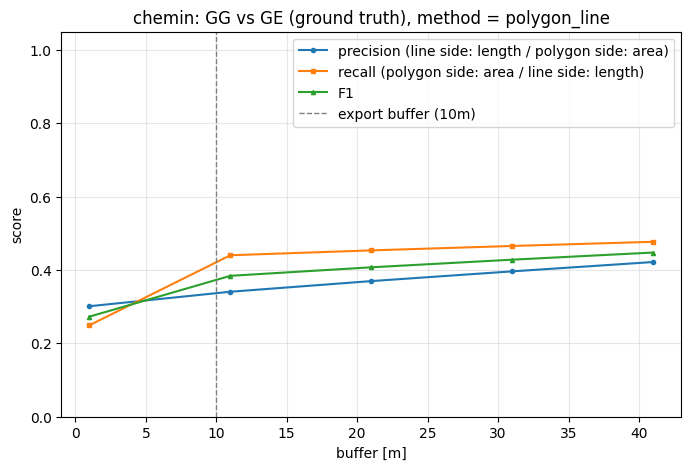

In [22]:
rows = []
xcol = f"{PARAM_NAME.replace(' ', '_')}_{PARAM_UNIT}"
for b in PARAM_RANGE:
    m, _, _ = compare(gt, test, float(b))
    rows.append({xcol: float(b), **m})
sweep = pd.DataFrame(rows)
sweep.to_csv(os.path.join(out_dir, f"{attribute}_metrics_vs_{ptag}.csv"), index=False)
display(sweep)

if sweep[["precision", "recall", "F1"]].isna().all().all():
    print(f"No metrics for method '{method}' (dummy function): nothing to plot.")
else:
    labels = {"point": ("precision", "recall"),
              "line": ("precision (correctness, length)", "recall (completeness, length)"),
              "polygon": ("precision (area)", "recall (area)"),
              "polygon_line": ("precision (line side: length / polygon side: area)",
                               "recall (polygon side: area / line side: length)"),
              "vitesse": ("precision (correct / lines with speed, length)", "recall (correct / matched lines, length)")}[method]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(sweep[xcol], sweep.precision, "o-", ms=3, label=labels[0])
    ax.plot(sweep[xcol], sweep.recall, "s-", ms=3, label=labels[1])
    ax.plot(sweep[xcol], sweep.F1, "^-", ms=3, label="F1")
    ax.axvline(PARAM_EXPORT, color="grey", ls="--", lw=1, label=f"export {PARAM_NAME} ({btag})")
    ax.set(xlabel=f"{PARAM_NAME} [{PARAM_UNIT.replace('kmh', 'km/h')}]", ylabel="score", ylim=(0, 1.05),
           title=f"{attribute}: GG vs GE (ground truth), method = {method}")
    ax.grid(alpha=0.3); ax.legend()
    fig.savefig(os.path.join(out_dir, f"{attribute}_metrics_vs_{ptag}.png"), dpi=150, bbox_inches="tight")
    plt.show()

## Reading the results

* **Curve plateau**: if recall keeps rising beyond about 10–15 m, the gap comes from **positional offset** (e.g. OSM node on the other side of the street) rather than missing objects. The relevant buffer is where the curve flattens.
* **Low precision**: before blaming OSM, check the **definition** (tags kept vs SITG filter) and the **date** of both sources. Open the FP file in QGIS.
* **Border**: objects just outside the canton are cut away, so a few FN/FP can appear along the border.
* For **lines/polygons**, precision/recall are length/area shares (global), while the FN/FP files list features with less than `*_MIN_SHARE` covered (column `covered_share`).

## Etude pour traversées

In [52]:
# ============ Custom comparison: two layers given by full path ============
###----change here-----
CUSTOM_NAME = "feu_signalisation"                  # name of the output sub-folder

CUSTOM_GG_PATH = "/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/networkGG/walk_crossing_nodes.geojson"  # layer to evaluate (OSM)
CUSTOM_GG_LAYER = None                          # layer name if multi-layer GeoPackage, else None
CUSTOM_GG_COLUMN = "crossing"
CUSTOM_GG_VALUES = ["traffic_signals"]

CUSTOM_GE_PATH = "/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/attributs/GE/OTC_SL_EQUIPEMENT_BOITEFEUX-SHP/OTC_SL_EQUIPEMENT_BOITEFEUX.shp"   # ground truth (SITG)
CUSTOM_GE_LAYER = None
CUSTOM_GE_COLUMN = None
CUSTOM_GE_VALUES = None

CUSTOM_BUFFER_EXPORT = 10                       # [m] buffer used to export FN / FP
CUSTOM_BUFFER_RANGE = np.arange(1, 51, 1)       # [m] buffers for the curve
CUSTOM_CLIP_TO_DOMAIN = True                    # restrict both layers to the canton (domain loaded above)
CUSTOM_FORCE_POINTS = False                     # True: lines -> midpoint, polygons -> point on surface (if one layer is points, the other lines)

# Fusion des feux proches
FUSION = True          # True : fusionne les feux dans un rayon donné ; False : garde les points bruts
FUSION_RADIUS = 15.0   # rayon de fusion en mètres
CRS_METRIQUE = 2056    # CH1903+/LV95, valable pour tout le Grand Genève
###--------------------

In [46]:
def load_custom_layer(path, layer, column, values, label):
    """Read a layer from a full path. If `column` is None, keep every feature;
    otherwise keep the features whose `column` is in `values`."""
    if layer is None and path.lower().endswith(".gpkg"):
        layers = list(pyogrio.list_layers(path)[:, 0])
        if len(layers) > 1:
            raise ValueError(f"[{label}] {path} has several layers {layers}: set the layer name.")
    gdf = read_vector(path, layer=layer)
    if column is None:
        print(f"[{label}] {path}: {len(gdf):,} features, all kept (no filter)\n")
    else:
        if column not in gdf.columns:
            raise KeyError(f"[{label}] column '{column}' not found. Columns: {list(gdf.columns)}")
        print(f"[{label}] {path}: {len(gdf):,} features. Values of '{column}':")
        print(gdf[column].value_counts(dropna=False).head(20).to_string())
        keep = gdf[column].astype(str).str.strip().isin([str(v) for v in values])
        gdf = gdf[keep]
        print(f"  -> {len(gdf):,} kept with {column} in {values}\n")
    if gdf.crs is None:
        print(f"  Warning: no CRS, assuming {operation_crs}")
        gdf = gdf.set_crs(operation_crs)
    gdf = gdf.to_crs(operation_crs)
    gdf["geometry"] = gdf["geometry"].apply(clean_any_geom)
    return gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].reset_index(drop=True)

def to_points(gdf):
    """Lines -> midpoint, polygons -> point on surface, points unchanged."""
    gdf = gdf.explode(index_parts=False, ignore_index=True)
    geoms = np.asarray(gdf.geometry.array, dtype=object)
    t = gdf.geom_type.values
    is_line, is_poly = np.isin(t, ["LineString", "LinearRing"]), t == "Polygon"
    if is_line.any():
        geoms[is_line] = shapely.line_interpolate_point(geoms[is_line], 0.5, normalized=True)
    if is_poly.any():
        geoms[is_poly] = shapely.point_on_surface(geoms[is_poly])
    return gdf.set_geometry(gpd.GeoSeries(geoms, index=gdf.index, crs=gdf.crs))


def save_gpkg(gdf, path, layer):   # same as in the export cell, redefined so this block is self-sufficient
    if gdf is None or len(gdf) == 0:
        print(f"  {layer}: empty, nothing written")
        return
    gdf.to_file(path, layer=layer, driver="GPKG")
    print(f"  {layer}: {len(gdf):,} features -> {path}")

    import numpy as np
import geopandas as gpd
from scipy.spatial import cKDTree

def fusion_points(gdf, radius, keep_cols=None, crs_metrique=CRS_METRIQUE):
    if gdf.empty:
        return gdf.copy()
    keep_cols = [c for c in (keep_cols or []) if c in gdf.columns]

    crs_origine = gdf.crs
    g = gdf.to_crs(crs_metrique).reset_index(drop=True)
    xy = np.column_stack([g.geometry.x, g.geometry.y])
    voisins = cKDTree(xy).query_ball_point(xy, r=radius)
    ordre = np.argsort([-len(v) for v in voisins], kind="stable")

    traite = np.zeros(len(g), dtype=bool)
    rows = []
    for i in ordre:
        if traite[i]:
            continue
        groupe = [j for j in voisins[i] if not traite[j]]
        traite[groupe] = True
        cx, cy = xy[groupe].mean(axis=0)
        row = {"n_fusion": len(groupe), "x": cx, "y": cy}
        for c in keep_cols:
            m = g.loc[groupe, c].mode()
            row[c] = m.iloc[0] if len(m) else None
        rows.append(row)

    out = pd.DataFrame(rows)
    out = gpd.GeoDataFrame(out.drop(columns=["x", "y"]),
                           geometry=gpd.points_from_xy(out["x"], out["y"]),
                           crs=crs_metrique)
    return out.to_crs(crs_origine)

In [53]:
c_gt = load_custom_layer(CUSTOM_GE_PATH, CUSTOM_GE_LAYER, CUSTOM_GE_COLUMN, CUSTOM_GE_VALUES, "GE")
c_test = load_custom_layer(CUSTOM_GG_PATH, CUSTOM_GG_LAYER, CUSTOM_GG_COLUMN, CUSTOM_GG_VALUES, "GG")

if CUSTOM_CLIP_TO_DOMAIN:
    c_gt = gpd.clip(c_gt, domain).reset_index(drop=True)
    c_test = gpd.clip(c_test, domain).reset_index(drop=True)
if CUSTOM_FORCE_POINTS:
    c_gt, c_test = to_points(c_gt), to_points(c_test)

c_fam_gt, c_cnt_gt = geom_family(c_gt)
c_fam_test, c_cnt_test = geom_family(c_test)
print(f"GE: {len(c_gt):,} features | {c_cnt_gt.to_dict()}")
print(f"GG: {len(c_test):,} features | {c_cnt_test.to_dict()}")

if c_fam_gt != c_fam_test:
    c_compare, c_method = mixed_metrics, "mixed"
    print("Different geometry types -> mixed (dummy). Set CUSTOM_FORCE_POINTS = True to compare as points.")
else:
    c_compare, c_method = COMPARATORS[c_fam_gt], c_fam_gt
    c_gt, c_test = harmonize(c_gt, c_fam_gt), harmonize(c_test, c_fam_test)
print(f"-> comparison method: {c_method} ({c_compare.__name__})")

# --- Fusion des points proches (GE et GG séparément) ---
c_ftag = ""
if FUSION:
    all_points = (c_gt.geom_type.eq("Point").all() and c_test.geom_type.eq("Point").all())
    if all_points:
        n_gt, n_test = len(c_gt), len(c_test)
        c_gt = fusion_points(c_gt, FUSION_RADIUS, keep_cols=[CUSTOM_GE_COLUMN])
        c_test = fusion_points(c_test, FUSION_RADIUS, keep_cols=[CUSTOM_GG_COLUMN])
        c_ftag = f"_fusion{FUSION_RADIUS:g}m"
        print(f"-> fusion (r = {FUSION_RADIUS:g} m): GE {n_gt:,} -> {len(c_gt):,} | GG {n_test:,} -> {len(c_test):,}")
    else:
        print("-> FUSION ignorée : les deux couches doivent être des points (CUSTOM_FORCE_POINTS = True).")

c_out_dir = os.path.join(output_comparison_path, CUSTOM_NAME)
os.makedirs(c_out_dir, exist_ok=True)
c_btag = f"{CUSTOM_BUFFER_EXPORT:g}m"

c_metrics, c_fn, c_fp = c_compare(c_gt, c_test, CUSTOM_BUFFER_EXPORT)
print(f"\n[{CUSTOM_NAME} | {c_method}{' + fusion' if c_ftag else ''} | buffer = {c_btag}]")
for k, v in c_metrics.items():
    print(f"  {k:>18}: {v:,.3f}" if isinstance(v, float) else f"  {k:>18}: {v:,}")

if len(c_fp) and CUSTOM_GG_COLUMN in c_fp.columns:
    print(f"\nGG kept vs FP by '{CUSTOM_GG_COLUMN}':")
    display(pd.DataFrame({"GG_kept": c_test[CUSTOM_GG_COLUMN].value_counts(),
                          "FP": c_fp[CUSTOM_GG_COLUMN].value_counts()}).fillna(0).astype(int))

save_gpkg(c_fn, os.path.join(c_out_dir, f"{CUSTOM_NAME}_FN_missing_in_GG_buffer{c_btag}{c_ftag}.gpkg"), f"FN_{CUSTOM_NAME}")
save_gpkg(c_fp, os.path.join(c_out_dir, f"{CUSTOM_NAME}_FP_absent_from_GE_buffer{c_btag}{c_ftag}.gpkg"), f"FP_{CUSTOM_NAME}")

[GE] /Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/attributs/GE/OTC_SL_EQUIPEMENT_BOITEFEUX-SHP/OTC_SL_EQUIPEMENT_BOITEFEUX.shp: 11,726 features, all kept (no filter)

[GG] /Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/networkGG/walk_crossing_nodes.geojson: 17,168 features. Values of 'crossing':
crossing
uncontrolled                    8168
None                            2621
marked                          2280
unmarked                        2079
traffic_signals                 1820
zebra                            185
informal                          11
pavement                           2
uncontrolled;traffic_signals       1
island                             1
  -> 1,820 kept with crossing in ['traffic_signals']

GE: 11,724 features | {'point': 11724}
GG: 1,518 features | {'point': 1518}
-> comparison method: point (point_metrics)
-> fusion (r = 15 m): GE 11,724 -> 2,038 | GG 1,518 -> 922

[feu_signalisation | point + fusion | buffer

,GG_kept,FP
crossing,,
traffic_signals,922,134


  FN_feu_signalisation: 1,250 features -> ../../Data/output/walk/comparison_GG_vs_GE/feu_signalisation/feu_signalisation_FN_missing_in_GG_buffer10m_fusion15m.gpkg
  FP_feu_signalisation: 134 features -> ../../Data/output/walk/comparison_GG_vs_GE/feu_signalisation/feu_signalisation_FP_absent_from_GE_buffer10m_fusion15m.gpkg


,buffer_m,TP,FN,FP,precision,recall,F1
0,1.0,43,1995,879,0.046638,0.021099,0.029054
1,2.0,113,1925,809,0.122560,0.055447,0.076351
2,3.0,212,1826,710,0.229935,0.104024,0.143243
3,4.0,301,1737,621,0.326464,0.147694,0.203378
4,5.0,397,1641,525,0.430586,0.194799,0.268243
5,6.0,504,1534,418,0.546638,0.247301,0.340541
6,7.0,587,1451,335,0.636659,0.288027,0.396622
7,8.0,667,1371,255,0.723427,0.327282,0.450676
8,9.0,736,1302,186,0.798265,0.361138,0.497297
9,10.0,788,1250,134,0.854664,0.386654,0.532432


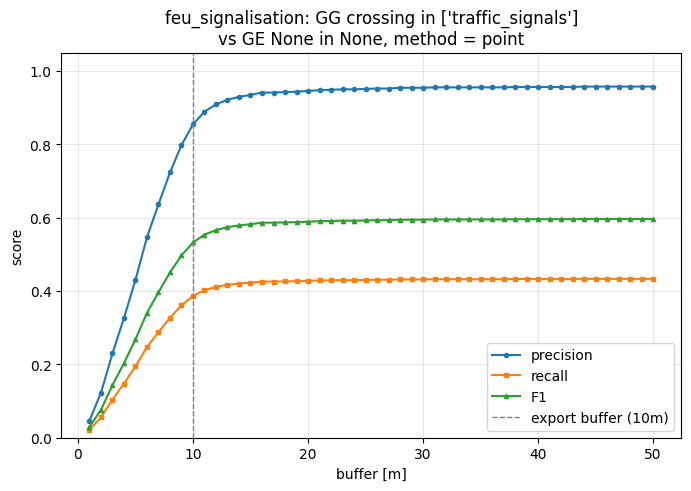

In [54]:
c_rows = [{"buffer_m": float(b), **c_compare(c_gt, c_test, float(b))[0]} for b in CUSTOM_BUFFER_RANGE]
c_sweep = pd.DataFrame(c_rows)
c_sweep.to_csv(os.path.join(c_out_dir, f"{CUSTOM_NAME}_metrics_vs_buffer.csv"), index=False)
display(c_sweep)

if c_sweep[["precision", "recall", "F1"]].isna().all().all():
    print(f"No metrics for method '{c_method}': nothing to plot.")
else:
    c_labels = {"point": ("precision", "recall"),
                "line": ("precision (correctness, length)", "recall (completeness, length)"),
                "polygon": ("precision (area)", "recall (area)")}[c_method]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(c_sweep.buffer_m, c_sweep.precision, "o-", ms=3, label=c_labels[0])
    ax.plot(c_sweep.buffer_m, c_sweep.recall, "s-", ms=3, label=c_labels[1])
    ax.plot(c_sweep.buffer_m, c_sweep.F1, "^-", ms=3, label="F1")
    ax.axvline(CUSTOM_BUFFER_EXPORT, color="grey", ls="--", lw=1, label=f"export buffer ({c_btag})")
    ax.set(xlabel="buffer [m]", ylabel="score", ylim=(0, 1.05),
           title=f"{CUSTOM_NAME}: GG {CUSTOM_GG_COLUMN} in {CUSTOM_GG_VALUES}\nvs GE {CUSTOM_GE_COLUMN} in {CUSTOM_GE_VALUES}, method = {c_method}")
    ax.grid(alpha=0.3); ax.legend()
    fig.savefig(os.path.join(c_out_dir, f"{CUSTOM_NAME}_metrics_vs_buffer.png"), dpi=150, bbox_inches="tight")
    plt.show()